---
title: "L5-01 · States and the Born rule"
short_title: "States and the Born rule"
subtitle: "A qubit state is a unit vector of complex amplitudes; the Born rule turns the amplitudes in a chosen basis into probabilities, and a global phase never changes any of them while a relative phase can."
description: "Calculate measurement probabilities from normalized amplitudes in a stated basis, and place a qubit state on the Bloch sphere."
tags: [level-5, coursebook]
---

(lesson-l5-01)=

:::{div}
:class: qcai-meta
![Level 5 icon](../../_static/icons/qicon-level-5.svg) **Level 5 · Advanced undergraduate** · about 90 minutes  
**Big idea.** A qubit state is a unit vector of complex amplitudes; the Born rule turns the amplitudes in a chosen basis into probabilities, and a global phase never changes any of them while a relative phase can.  
**Before this lesson.** [L3-01](#lesson-l3-01), [L3-02](#lesson-l3-02)  
**Lab.** [Qubits and the Bloch sphere](../../labs/05-qubit-bloch.ipynb)
:::

## What you will be able to do

- Normalize a state vector and compute Born-rule probabilities $|\langle b|\psi\rangle|^2$ in the computational basis and in the bases $\{|+\rangle, |-\rangle\}$ and $\{|{+i}\rangle, |{-i}\rangle\}$.
- Convert between amplitudes and Bloch angles $(\theta, \varphi)$, and use $P(0) = (1 + z)/2$ and its $x$ and $y$ versions.
- Prove that a global phase changes no measurement probability, and give two states with identical computational-basis statistics that another basis tells apart.
- Estimate a probability from $n$ shots and state its standard error $\sqrt{p(1-p)/n}$.

## Why this matters

Prepare the state $|+\rangle = (|0\rangle + |1\rangle)/\sqrt2$ a thousand times and measure each copy in the computational basis: about half the outcomes are 0. Do the same with $|-\rangle = (|0\rangle - |1\rangle)/\sqrt2$: again about half are 0. The two lists of counts are indistinguishable. Yet the two states are orthogonal, which means a different measurement tells them apart perfectly, every single time. So a list of outcome probabilities is not the state, and a minus sign that seems to vanish when you square it can decide everything.

The Born rule is the one bridge between the vectors of quantum theory and the counts that come out of a laboratory or a cloud quantum computer. Every later lesson in this level uses it: gates change amplitudes ([L5-02](#lesson-l5-02)), interference turns relative phase into counts ([L5-03](#lesson-l5-03)), and tomography reconstructs a state from many bases ([L5-09](#lesson-l5-09)). This lesson states the rule carefully, proves what it can and cannot see, and connects it to the statistics of repeated shots.

:::{dropdown} Key terms

**Pure qubit state**
: A unit vector $|\psi\rangle = \alpha|0\rangle + \beta|1\rangle$ in $\mathbb{C}^2$, with $|\alpha|^2 + |\beta|^2 = 1$.

**Computational basis**
: The orthonormal basis $|0\rangle = (1, 0)^T$, $|1\rangle = (0, 1)^T$ in which a qubit is usually measured.

**Born rule**
: Measuring in an orthonormal basis $\{|b_k\rangle\}$ gives outcome $k$ with probability $|\langle b_k|\psi\rangle|^2$.

**Global phase**
: A common factor $e^{i\gamma}$ multiplying every amplitude; it changes no probability in any basis.

**Relative phase**
: The phase difference $\varphi$ between two amplitudes, as in $\alpha|0\rangle + e^{i\varphi}\beta|1\rangle$ with $\alpha, \beta \ge 0$; it can change probabilities in other bases.

**Bloch vector**
: The point $(\sin\theta\cos\varphi, \sin\theta\sin\varphi, \cos\theta)$ on the unit sphere that represents $\cos\frac{\theta}{2}|0\rangle + e^{i\varphi}\sin\frac{\theta}{2}|1\rangle$.

**Shot**
: One preparation followed by one measurement; it returns a single outcome.

:::


In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))
from qcai.viz import show as _show, show_mpl as _show_mpl
from qcai.lessonfigs import l5_01 as _lessonfigs

## State vectors

A qubit is described in the two-dimensional complex vector space $\mathbb{C}^2$ with the computational basis $|0\rangle = (1, 0)^T$ and $|1\rangle = (0, 1)^T$. A column vector is written $|\psi\rangle$ (a ket); its conjugate transpose is the row vector $\langle\psi|$ (a bra). The inner product of [L3-02](#lesson-l3-02) is $\langle\phi|\psi\rangle = \sum_k \overline{\phi_k}\,\psi_k$, conjugate-linear in the first slot.

:::{prf:definition} Pure qubit state
:label: def-l5-01-state
A **pure state** of a qubit is a vector $|\psi\rangle = \alpha|0\rangle + \beta|1\rangle$ with complex **amplitudes** $\alpha, \beta$ and unit length, $\langle\psi|\psi\rangle = |\alpha|^2 + |\beta|^2 = 1$. Two unit vectors that differ only by a factor $e^{i\gamma}$ describe the same physical state (this is justified by Proposition [](#prop-l5-01-global) below).
:::

$$
|\psi\rangle = \alpha|0\rangle + \beta|1\rangle, \qquad |\alpha|^2 + |\beta|^2 = 1
$$ (eq-l5-01-state)

Any nonzero vector can be normalized by dividing by its length. For $v = (1, 2i)^T$ the length is $\sqrt{1 + |2i|^2} = \sqrt5$, so $|\psi\rangle = \frac{1}{\sqrt5}|0\rangle + \frac{2i}{\sqrt5}|1\rangle$. Notice $|2i|^2 = (2i)(-2i) = 4$: the modulus squared uses the conjugate, as in [L3-01](#lesson-l3-01).

## The Born rule

:::{prf:definition} Born rule for a measurement in an orthonormal basis
:label: def-l5-01-born
Measuring a qubit in state $|\psi\rangle$ in an orthonormal basis $\{|b_0\rangle, |b_1\rangle\}$ gives outcome $k$ with probability $P(k) = |\langle b_k|\psi\rangle|^2$. In the computational basis this is $P(0) = |\alpha|^2$ and $P(1) = |\beta|^2$. (After an ideal measurement the qubit is left in $|b_k\rangle$; [L5-07](#lesson-l5-07) treats general measurements.)
:::

$$
P(k) = |\langle b_k|\psi\rangle|^2, \qquad P(0) = |\alpha|^2, \quad P(1) = |\beta|^2
$$ (eq-l5-01-born)

:::{prf:proposition} Born probabilities form a distribution
:label: prop-l5-01-dist
For every unit vector $|\psi\rangle$ and every orthonormal basis $\{|b_k\rangle\}$, the numbers $P(k) = |\langle b_k|\psi\rangle|^2$ are non-negative and sum to 1.
:::

:::{prf:proof}
Each $P(k)$ is a squared modulus, so $P(k) \ge 0$. Write $|\psi\rangle = \sum_k c_k |b_k\rangle$ with $c_k = \langle b_k|\psi\rangle$ (expansion in an orthonormal basis). Then $1 = \langle\psi|\psi\rangle = \sum_{j,k} \overline{c_j} c_k \langle b_j|b_k\rangle = \sum_k |c_k|^2 = \sum_k P(k)$, because $\langle b_j|b_k\rangle$ is 1 when $j = k$ and 0 otherwise.
:::

Take $|\psi\rangle = \frac{\sqrt3}{2}|0\rangle + \frac12|1\rangle$. Then $P(0) = \frac34$ and $P(1) = \frac14$. In 400 independent shots the expected number of 1s is $400 \cdot \frac14 = 100$, and the standard deviation of that count is $\sqrt{400 \cdot \frac14 \cdot \frac34} \approx 8.66$. One seeded run (the one in the animation and the code below) gives 95 ones, about half a standard deviation low; after 4000 shots it gives 990 against an expected 1000.

:::{figure} ../../_static/animations/l5_01_born_rule_shots.mp4
:alt: Amplitude bars of height root 3 over 2 and one half turn into probability bars 3/4 and 1/4; then frequency bars and a running-frequency curve settle inside a shrinking band as the number of shots grows to 4000.
:width: 100%

The Born rule squares amplitudes into probabilities; repeated shots only estimate them, with an error that shrinks like $1/\sqrt n$.
:::

:::{dropdown} What the animation shows
The state $\frac{\sqrt3}{2}|0\rangle + \frac12|1\rangle$ is shown with two blue bars of heights $\alpha = \frac{\sqrt3}{2}$ and $\beta = \frac12$. The bars shrink into violet bars of heights $|\alpha|^2 = \frac34$ and $|\beta|^2 = \frac14$, labeled with the Born rule $P(k) = |\langle k|\psi\rangle|^2$. Dashed lines keep those heights as targets while new bars show the observed fractions of 0s and 1s in a growing number of shots. On the right, the fraction of 1s is plotted against the number of shots on a log scale inside the band $\frac14 \pm 2\sqrt{p(1-p)/n}$. At $n = 400$ the run has 95 ones, against an expected 100 with standard deviation $\approx 8.66$. At $n = 4000$ it has 990 ones, against an expected 1000; the curve hugs $\frac14$.
:::

:::{warning} Amplitudes do not add to 1
The state $(|0\rangle - |1\rangle)/\sqrt2$ has amplitudes adding to $0$, and $\frac{1}{\sqrt5}|0\rangle + \frac{2i}{\sqrt5}|1\rangle$ has amplitudes adding to a complex number. Only the squared moduli add to 1. Negative and complex amplitudes are allowed; negative probabilities are not.
:::

## Global phase, relative phase, and the Bloch sphere

:::{prf:proposition} A global phase is unobservable
:label: prop-l5-01-global
For every real $\gamma$, every state $|\psi\rangle$ and every orthonormal basis $\{|b_k\rangle\}$, the states $|\psi\rangle$ and $e^{i\gamma}|\psi\rangle$ give the same probabilities: $|\langle b_k|e^{i\gamma}\psi\rangle|^2 = |\langle b_k|\psi\rangle|^2$.
:::

:::{prf:proof}
The inner product is linear in its second slot, so $\langle b_k|e^{i\gamma}\psi\rangle = e^{i\gamma}\langle b_k|\psi\rangle$. The modulus is multiplicative and $|e^{i\gamma}| = 1$, so the squared moduli agree.
:::

A **relative** phase is different. The states $|\pm\rangle = (|0\rangle \pm |1\rangle)/\sqrt2$ differ only by the sign of one amplitude, and both give $P(0) = P(1) = \frac12$. But in the basis $\{|+\rangle, |-\rangle\}$ itself, $|\langle +|+\rangle|^2 = 1$ while $|\langle +|-\rangle|^2 = 0$. A global phase multiplies all amplitudes together; a relative phase changes one amplitude against another, and that is what other bases detect.

:::{prf:theorem} Bloch parametrization
:label: thm-l5-01-bloch
Every pure qubit state equals, up to a global phase, $\cos\frac{\theta}{2}|0\rangle + e^{i\varphi}\sin\frac{\theta}{2}|1\rangle$ for some $\theta \in [0, \pi]$ and $\varphi \in [0, 2\pi)$. The angle $\theta$ is unique, and $\varphi$ is unique except at the poles $\theta = 0$ and $\theta = \pi$, where it plays no role.
:::

:::{prf:proof}
Write $\alpha = |\alpha|e^{ia}$ and $\beta = |\beta|e^{ib}$. Multiplying by the global phase $e^{-ia}$ (allowed by Proposition [](#prop-l5-01-global)) gives $|\alpha|\,|0\rangle + e^{i(b - a)}|\beta|\,|1\rangle$. Since $|\alpha|^2 + |\beta|^2 = 1$ and both are non-negative, there is exactly one $\theta/2 \in [0, \pi/2]$ with $\cos\frac{\theta}{2} = |\alpha|$ and $\sin\frac{\theta}{2} = |\beta|$. Put $\varphi = b - a$ reduced modulo $2\pi$. If $\alpha$ and $\beta$ are both nonzero, $a$ and $b$ are determined modulo $2\pi$, so $\varphi$ is unique. If $\beta = 0$ ($\theta = 0$) or $\alpha = 0$ ($\theta = \pi$, after removing the phase of $\beta$ instead), the factor $e^{i\varphi}$ multiplies a zero amplitude or becomes global, so any $\varphi$ gives the same state.
:::

$$
\vec r = (\sin\theta\cos\varphi,\ \sin\theta\sin\varphi,\ \cos\theta), \qquad P(0) = \cos^2\tfrac{\theta}{2} = \tfrac{1 + z}{2}
$$ (eq-l5-01-bloch)

The last identity is the half-angle formula $\cos^2\frac{\theta}{2} = \frac{1 + \cos\theta}{2}$. So the probability of outcome 0 is read off the sphere by projecting the point onto the vertical axis. The example state $\frac{\sqrt3}{2}|0\rangle + \frac12|1\rangle$ has $\theta = 60^\circ$, $z = 0.5$ and $P(0) = 0.750$. Conventions: $\theta$ is measured from the $+z$ axis (the state $|0\rangle$), and $\varphi$ from the $+x$ axis toward $+y$.

:::{figure} ../../_static/animations/l5_01_bloch_sphere_born.mp4
:alt: A Bloch sphere with a violet state arrow that tilts down from the north pole, a dashed amber projection onto the vertical axis, and a live readout of P(0); the arrow then circles at fixed height and finally two small amplitude dials spin while the arrow stays still.
:width: 100%

Height on the sphere is probability: $P(0) = (1 + z)/2$. Turning $\varphi$ keeps the height; a global phase $e^{i\gamma}$ does not move the point at all.
:::

:::{dropdown} What the animation shows
A Bloch sphere is drawn with $|0\rangle$ at the top, $|1\rangle$ at the bottom, and the $x$ and $y$ axes. Next to it is the formula $|\psi\rangle = \cos\frac{\theta}{2}|0\rangle + e^{i\varphi}\sin\frac{\theta}{2}|1\rangle$ and three live readouts: $\theta$ in degrees, $z = \cos\theta$, and $P(0) = \frac{1 + z}{2}$. The state arrow starts at the north pole ($P(0) = 1$) and tilts to $\theta = 120^\circ$ ($P(0) = 0.25$), with a dashed amber line projecting its tip onto the vertical axis, then returns to $\theta = 60^\circ$, where $P(0) = \frac34 = 0.750$. Next $\varphi$ runs once around: the tip traces a cyan circle of constant height while the readout stays at 0.750. Finally two dials show the amplitudes $\alpha$ and $\beta$ as arrows; under a global phase $e^{i\gamma}|\psi\rangle$ both arrows spin together through a full turn, while the Bloch point does not move: same point, same probabilities.
:::


In [2]:
_show(_lessonfigs.bloch_explorer())

**Explore.** Drag the polar angle $\theta$. The cyan ring is every state with that $\theta$ (all $\varphi$); they share the same $P(0)$, which is the height of the amber projection.

:::{dropdown} What the figure shows
A 3-D Bloch sphere with $|0\rangle$ at the top. A slider sets $\theta$ from $0^\circ$ to $180^\circ$ in steps of $15^\circ$, starting at $60^\circ$. For each value the figure draws the latitude ring of all states with that $\theta$, one state on the ring at $\varphi = 60^\circ$, a dashed projection of that state onto the vertical axis, and the label $P(0) = \cos^2(\theta/2)$: 1.000 at $0^\circ$, 0.750 at $60^\circ$, 0.500 at $90^\circ$, 0.250 at $120^\circ$, and 0.000 at $180^\circ$. The figure can be rotated with the mouse.
:::

## Other bases reveal relative phase

:::{prf:definition} The X and Y bases
:label: def-l5-01-xy
$|\pm\rangle = \frac{1}{\sqrt2}(|0\rangle \pm |1\rangle)$ and $|{\pm i}\rangle = \frac{1}{\sqrt2}(|0\rangle \pm i|1\rangle)$. Each pair is orthonormal; on the Bloch sphere $|\pm\rangle$ sit at $(\pm1, 0, 0)$ and $|{\pm i}\rangle$ at $(0, \pm1, 0)$.
:::

:::{prf:theorem} Bloch components are measurable probabilities
:label: thm-l5-01-components
For a pure state with Bloch vector $(x, y, z)$, the three basis measurements give
:::

$$
P(+) = \tfrac{1 + x}{2}, \qquad P(+i) = \tfrac{1 + y}{2}, \qquad P(0) = \tfrac{1 + z}{2}
$$ (eq-l5-01-xyz)

:::{prf:proof}
Use $|\psi\rangle = \alpha|0\rangle + \beta|1\rangle$ with $\alpha = \cos\frac{\theta}{2}$ and $\beta = e^{i\varphi}\sin\frac{\theta}{2}$ (Theorem [](#thm-l5-01-bloch)). The $z$ case is [](#eq-l5-01-bloch). For $x$: $\langle +|\psi\rangle = (\alpha + \beta)/\sqrt2$, so $P(+) = \frac12(|\alpha|^2 + |\beta|^2 + 2\operatorname{Re}(\bar\alpha\beta)) = \frac12(1 + 2\cos\frac{\theta}{2}\sin\frac{\theta}{2}\cos\varphi) = \frac12(1 + \sin\theta\cos\varphi)$. For $y$: $\langle +i|\psi\rangle = (\alpha - i\beta)/\sqrt2$ (the bra conjugates $i$), and $\operatorname{Re}(\bar\alpha(-i\beta)) = \operatorname{Im}(\bar\alpha\beta) = \cos\frac{\theta}{2}\sin\frac{\theta}{2}\sin\varphi$, so $P(+i) = \frac12(1 + \sin\theta\sin\varphi)$.
:::

Apply this to the equator states $|\psi_\varphi\rangle = \frac{1}{\sqrt2}(|0\rangle + e^{i\varphi}|1\rangle)$, which have $z = 0$ and $x = \cos\varphi$. Every one of them gives $P(0) = \frac12$, but $P(+) = \tfrac{1 + \cos\varphi}{2}$ runs from 1 to 0 as $\varphi$ goes from $0$ to $\pi$. This is why the measurement basis must always be stated. (For any axis $\vec n$ the same rule holds, $P(+\vec n) = (1 + \vec n\cdot\vec r)/2$; the proof is easiest with density operators in [L5-05](#lesson-l5-05).)

:::{figure} ../../_static/animations/l5_01_basis_reveal.mp4
:alt: A state arrow runs around the equator of the Bloch sphere. A Z-basis bar chart stays at one half and one half while an X-basis bar chart swings between all plus and all minus, following the projection onto the x axis.
:width: 100%

The equator states $\frac{1}{\sqrt2}(|0\rangle + e^{i\varphi}|1\rangle)$ all look the same to a Z measurement; an X measurement reads the relative phase through $P(+) = \frac{1 + \cos\varphi}{2}$.
:::

:::{dropdown} What the animation shows
The state $|\psi_\varphi\rangle = \frac{1}{\sqrt2}(|0\rangle + e^{i\varphi}|1\rangle)$ is drawn on the equator of the Bloch sphere, with a dashed blue line projecting it onto the $x$ axis. Two bar charts are pinned beside the sphere. The Z-basis chart has bars for outcomes 0 and 1, both at height $\frac12$, with the note $P(0) = \frac12$ for every $\varphi$. The X-basis chart has bars for $+$ and $-$ with heights $\frac{1 + \cos\varphi}{2}$ and $\frac{1 - \cos\varphi}{2}$, and the formula $P(+) = \tfrac{1 + \cos\varphi}{2}$. As $\varphi$ runs from 0 to $2\pi$ the arrow circles the equator; the Z bars never move, while the X bars swing from all $+$ (at $\varphi = 0$) through equal (at $\varphi = \pi/2$) to all $-$ (at $\varphi = \pi$) and back. The scene ends at $\varphi = \pi$, the state $|-\rangle$: same Z statistics, different states.
:::

## From shots to probabilities

A single shot returns one bit; it never displays the amplitudes. With $n$ independent shots on identically prepared copies, the number $K$ of 1s is binomial with mean $np$ and variance $np(1-p)$ [@openstax_expected], so the observed frequency $\hat p = K/n$ estimates $p$ with standard error

$$
\operatorname{SE}(\hat p) = \sqrt{\frac{p(1 - p)}{n}}
$$ (eq-l5-01-se)


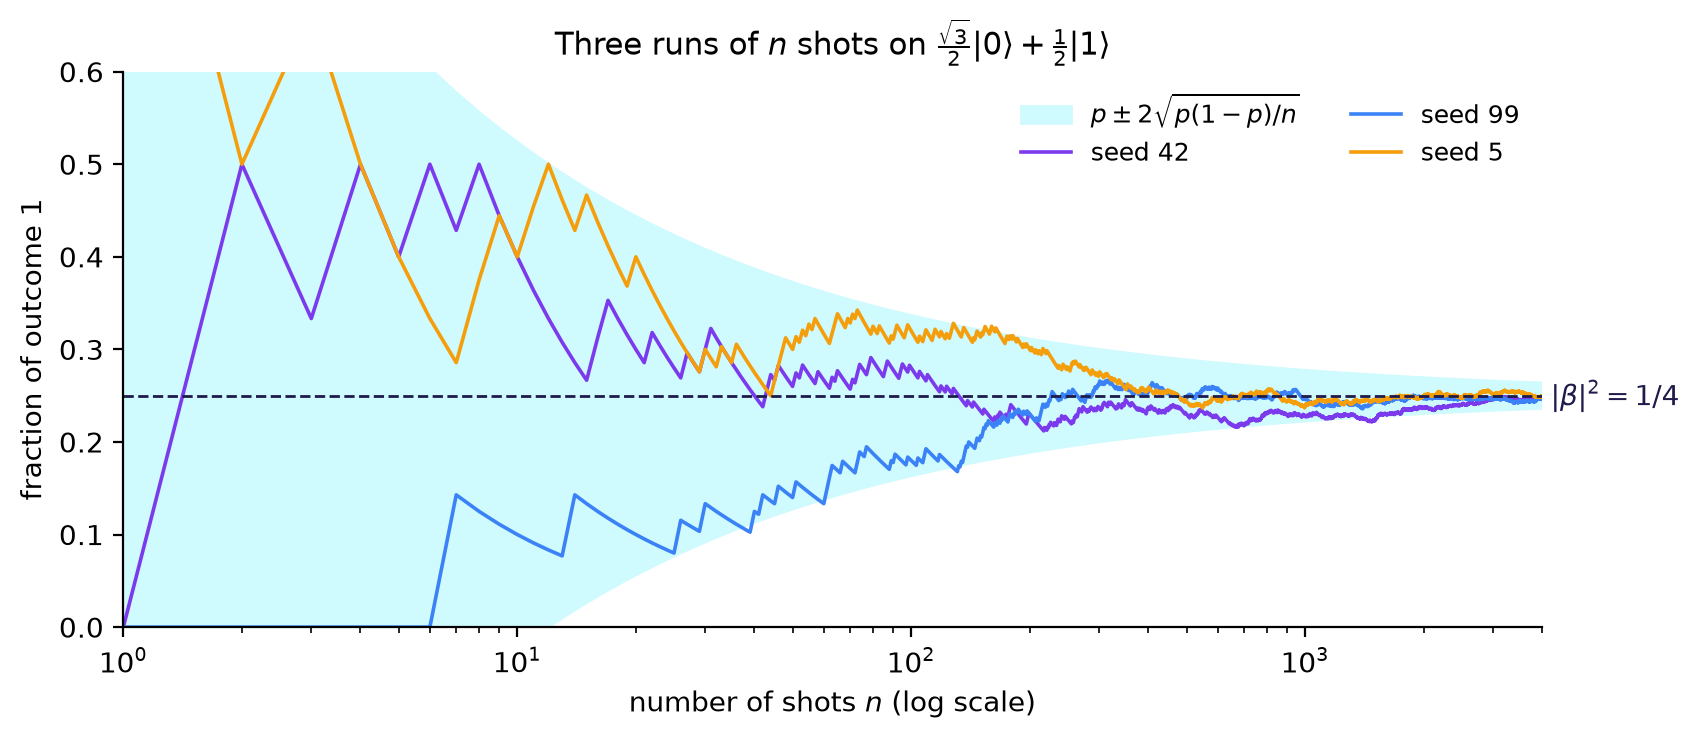

In [3]:
_show_mpl(_lessonfigs.shots_convergence())

*Three seeded runs of shots on $\frac{\sqrt3}{2}|0\rangle + \frac12|1\rangle$. Early frequencies wander widely; by a few thousand shots they sit inside the band $p \pm 2\sqrt{p(1-p)/n}$ around $p = \frac14$. Halving the error costs four times the shots.*

```{mermaid}
graph LR
  P[Prepare the same state] --> B[Choose a basis]
  B --> M[Measure one shot]
  M --> C[Record 0 or 1]
  C -->|repeat n times| P
  C --> E[Estimate p and its SE]
  E --> T[Compare bases to learn phase]
```

*Probabilities are learned only from repeated, identically prepared shots; relative phase needs more than one measurement basis.*

Normalize a state, apply the Born rule in three bases, confirm that a global phase changes nothing, recover the Bloch angles, and simulate shots with the same seeded generator as the animation.


In [4]:
import numpy as np
from qcai import science

# 1. normalize, then apply the Born rule in the computational basis
v = np.array([1, 2j])
psi = v / np.linalg.norm(v)
p = np.abs(psi) ** 2
print('amplitudes', np.round(psi, 4), ' probabilities', np.round(p, 4), ' sum', round(p.sum(), 12))

# 2. a global phase changes nothing, in any basis (np.vdot conjugates its first argument)
plus = np.array([1, 1]) / np.sqrt(2)
plus_i = np.array([1, 1j]) / np.sqrt(2)
def prob(b, s):
    return abs(np.vdot(b, s)) ** 2
g = np.exp(0.7j) * psi
print('P(+)  without and with a global phase:', round(prob(plus, psi), 4), round(prob(plus, g), 4))
print('P(+i) without and with a global phase:', round(prob(plus_i, psi), 4), round(prob(plus_i, g), 4))

# 3. Bloch angles and the rule P = (1 + component) / 2 along x, y and z
theta = 2 * np.arccos(abs(psi[0]))
phi = np.angle(psi[1]) - np.angle(psi[0])
x, y, z = science.bloch(science.dm(psi))
print('theta =', round(np.degrees(theta), 2), 'deg   phi =', round(np.degrees(phi), 2), 'deg')
print('Bloch vector', np.round([x, y, z], 4))
print('(1+x)/2, (1+y)/2, (1+z)/2 =', round((1 + x) / 2, 4), round((1 + y) / 2, 4), round((1 + z) / 2, 4))

# 4. shots on sqrt(3)/2 |0> + 1/2 |1>, with the same seeded generator as the animation
run = science.trials(0.25, 4000, seed=42)
for n in (10, 100, 400, 4000):
    ones = round(run['trace'][n - 1] * n)
    se = np.sqrt(0.25 * 0.75 / n)
    print(f'n = {n:5d}  ones = {ones:4d}  expected = {0.25 * n:6.1f}  frequency = {ones / n:.4f}  SE = {se:.4f}')

amplitudes [0.4472+0.j     0.    +0.8944j]  probabilities [0.2 0.8]  sum 1.0
P(+)  without and with a global phase: 0.5 0.5
P(+i) without and with a global phase: 0.9 0.9
theta = 126.87 deg   phi = 90.0 deg
Bloch vector [ 0.   0.8 -0.6]
(1+x)/2, (1+y)/2, (1+z)/2 = 0.5 0.9 0.2
n =    10  ones =    4  expected =    2.5  frequency = 0.4000  SE = 0.1369
n =   100  ones =   28  expected =   25.0  frequency = 0.2800  SE = 0.0433
n =   400  ones =   95  expected =  100.0  frequency = 0.2375  SE = 0.0217
n =  4000  ones =  990  expected = 1000.0  frequency = 0.2475  SE = 0.0068


:::{caution} What the counts do not tell you
Counts in one basis fix $|\alpha|$ and $|\beta|$ but say nothing about the relative phase; at least the X and Y bases are also needed ([L5-09](#lesson-l5-09)). Counts also do not explain themselves: matching the Born-rule prediction does not establish what caused a particular outcome.
:::

## Worked example

:::{admonition} One state, three bases
:class: tip

A qubit is prepared in $|\psi\rangle = \frac{1}{\sqrt5}|0\rangle + \frac{2i}{\sqrt5}|1\rangle$. Find $P(1)$, the expected number of 1s in 250 shots, the Bloch angles, and the probabilities $P(+)$ and $P(+i)$.

1. Check normalization: $|\frac{1}{\sqrt5}|^2 + |\frac{2i}{\sqrt5}|^2 = \frac15 + \frac45 = 1$.
2. Computational basis: $P(1) = |\frac{2i}{\sqrt5}|^2 = \frac45 = 0.8$, so the expected count in 250 shots is $250 \cdot 0.8 = 200$. The factor $i$ does not change this probability.
3. Bloch angles: $\cos\frac{\theta}{2} = \frac{1}{\sqrt5}$ gives $\theta = 2\arccos\frac{1}{\sqrt5} \approx 126.87^\circ$, and the phase of $2i/\sqrt5$ relative to $1/\sqrt5$ is $\varphi = 90^\circ$. So $z = \cos\theta = 2\cdot\frac15 - 1 = -\frac35$, $x = \sin\theta\cos\varphi = 0$, and $y = \sin\theta = 2\cdot\frac{1}{\sqrt5}\cdot\frac{2}{\sqrt5} = \frac45$.
4. Other bases from [](#eq-l5-01-xyz): $P(+) = \frac{1 + 0}{2} = \frac12$ and $P(+i) = \frac{1 + 4/5}{2} = \frac{9}{10}$. Directly: $\langle +i|\psi\rangle = \frac{1}{\sqrt2}\left(\frac{1}{\sqrt5} - i\cdot\frac{2i}{\sqrt5}\right) = \frac{3}{\sqrt{10}}$, whose square is $\frac{9}{10}$.

**Result.** $P(1) = 0.8$ (200 expected 1s in 250 shots), $(\theta, \varphi) \approx (126.87^\circ, 90^\circ)$, Bloch vector $(0, 0.8, -0.6)$, $P(+) = 0.5$ and $P(+i) = 0.9$. The relative phase $i$ is invisible in the Z and X bases but strongly visible in the Y basis.
:::

## Exercises

**1. (Core)** Normalize $v = 3|0\rangle + 4i|1\rangle$ and give $P(0)$ and $P(1)$.

:::{dropdown} Solution
$\|v\|^2 = 9 + 16 = 25$, so $|\psi\rangle = \frac35|0\rangle + \frac{4i}{5}|1\rangle$. Then $P(0) = \frac{9}{25} = 0.36$ and $P(1) = \frac{16}{25} = 0.64$.
:::

**2. (Core)** For $|\psi\rangle = \frac{1}{\sqrt2}(|0\rangle - i|1\rangle)$ find the outcome probabilities in the Z, X and Y bases, and its Bloch vector.

:::{dropdown} Solution
Z: $P(0) = P(1) = \frac12$. X: $\langle +|\psi\rangle = \frac12(1 - i)$, so $P(+) = \frac{|1 - i|^2}{4} = \frac12$. Y: $\langle +i|\psi\rangle = \frac12(1 - i\cdot(-i)) = \frac12(1 - 1) = 0$, so $P(+i) = 0$ and $P(-i) = 1$. The state is $|{-i}\rangle$, with Bloch vector $(0, -1, 0)$, consistent with $(1 + y)/2 = 0$.
:::

**3. (Stretch)** Show that $P(+) = \frac{1 + \cos\varphi}{2}$ for $|\psi_\varphi\rangle = \frac{1}{\sqrt2}(|0\rangle + e^{i\varphi}|1\rangle)$ directly from the Born rule, without the Bloch sphere. For which $\varphi$ is $P(+) = \frac14$?

:::{dropdown} Solution
$\langle +|\psi_\varphi\rangle = \frac12(1 + e^{i\varphi})$ and, as in [L3-01](#lesson-l3-01), $|1 + e^{i\varphi}|^2 = 2 + 2\cos\varphi$, so $P(+) = \frac{2 + 2\cos\varphi}{4} = \frac{1 + \cos\varphi}{2}$. Setting this to $\frac14$ gives $\cos\varphi = -\frac12$, so $\varphi = 2\pi/3$ or $4\pi/3$.
:::

**4. (Stretch)** How many shots guarantee a standard error of at most 0.01, whatever the true $p$? How many suffice if you know $p = \frac14$?

:::{dropdown} Solution
$p(1-p) \le \frac14$ with equality at $p = \frac12$, so $\sqrt{1/(4n)} \le 0.01$ requires $n \ge 2500$. With $p = \frac14$, $p(1-p) = \frac{3}{16}$ and $\sqrt{3/(16n)} \le 0.01$ requires $n \ge 1875$.
:::

**5. (Challenge)** Prove that two pure states $|\psi\rangle$ and $|\phi\rangle$ give the same outcome probabilities in every orthonormal basis if and only if $|\phi\rangle = e^{i\gamma}|\psi\rangle$ for some real $\gamma$.

:::{dropdown} Solution
If $|\phi\rangle = e^{i\gamma}|\psi\rangle$, Proposition [](#prop-l5-01-global) gives equal probabilities. Conversely, complete $|\psi\rangle$ to an orthonormal basis $\{|\psi\rangle, |\psi^\perp\rangle\}$ and measure in it. The state $|\psi\rangle$ gives the first outcome with probability 1, so by assumption $|\langle\psi|\phi\rangle|^2 = 1$. Both vectors have unit length, so Cauchy-Schwarz $|\langle\psi|\phi\rangle| \le \|\psi\|\|\phi\| = 1$ holds with equality, which happens only if $|\phi\rangle = c|\psi\rangle$; then $|c| = |\langle\psi|\phi\rangle| = 1$, so $c = e^{i\gamma}$.
:::

**6. (Challenge)** Show that antipodal points on the Bloch sphere are orthogonal states: the states with angles $(\theta, \varphi)$ and $(\pi - \theta, \varphi + \pi)$ have inner product 0.

:::{dropdown} Solution
The second state is $\cos\frac{\pi - \theta}{2}|0\rangle + e^{i(\varphi + \pi)}\sin\frac{\pi - \theta}{2}|1\rangle = \sin\frac{\theta}{2}|0\rangle - e^{i\varphi}\cos\frac{\theta}{2}|1\rangle$. Its inner product with $\cos\frac{\theta}{2}|0\rangle + e^{i\varphi}\sin\frac{\theta}{2}|1\rangle$ is $\cos\frac{\theta}{2}\sin\frac{\theta}{2} - e^{-i\varphi}\sin\frac{\theta}{2}\,e^{i\varphi}\cos\frac{\theta}{2} = 0$. So an orthonormal basis is a pair of opposite points; for example $|0\rangle, |1\rangle$ are the poles.
:::

## Check your understanding

**1. A state has amplitudes $0.6$ and $0.8i$. What is $P(1)$ in the computational basis?**

- **A.** 0.36
- **B.** 0.8
- **C.** -0.64
- **D.** 0.64

:::{dropdown} Show the answer
**D. 0.64**

$P(1) = |0.8i|^2 = (0.8i)(-0.8i) = 0.64$. The factor $i$ is a phase and does not change the modulus; 0.36 is $P(0)$.
:::

**2. Which change to a qubit state can alter the outcome probabilities of some measurement?**

- **A.** None: probabilities depend only on the moduli of the amplitudes
- **B.** Multiplying the whole state by $e^{i\pi/3}$
- **C.** Changing the relative phase between its two amplitudes
- **D.** Multiplying the whole state by $-1$

:::{dropdown} Show the answer
**C. Changing the relative phase between its two amplitudes**

A global factor of modulus 1 (including $-1$) changes no probability in any basis. A relative phase leaves Z probabilities alone but changes, for example, $P(+) = \frac{1 + \cos\varphi}{2}$ for equator states.
:::

**3. A pure state has Bloch vector with $z = -0.6$. What is $P(0)$?**

- **A.** -0.3
- **B.** 0.2
- **C.** 0.4
- **D.** 0.8

:::{dropdown} Show the answer
**B. 0.2**

$P(0) = \frac{1 + z}{2} = \frac{1 - 0.6}{2} = 0.2$.
:::

**4. Let $u = \frac{1}{\sqrt2}(1, i)^T$ and $v = \frac{1}{\sqrt2}(1, -i)^T$. What is the inner product $\langle u|v\rangle$?** *(Review of [L3-02](#lesson-l3-02))*

- **A.** $i$
- **B.** $\frac12$
- **C.** 1
- **D.** 0

:::{dropdown} Show the answer
**D. 0**

Conjugate the first vector: $\langle u|v\rangle = \frac12(\bar1\cdot1 + \bar i\cdot(-i)) = \frac12(1 + (-i)(-i)) = \frac12(1 - 1) = 0$. These are the states $|{+i}\rangle$ and $|{-i}\rangle$, an orthonormal basis.
:::

## Common misconceptions

- **"The amplitudes are the probabilities."** Probabilities are squared moduli $|\alpha|^2$ and $|\beta|^2$. Amplitudes can be negative or complex and need not add to 1.
- **"One measurement reveals the state."** One shot gives one outcome. Probabilities are estimated from many identically prepared copies, and the relative phase needs measurements in at least two further bases.
- **"A minus sign disappears when you square, so it never matters."** A global $-1$ never matters. A relative minus sign does: $|+\rangle$ and $|-\rangle$ give identical Z statistics but opposite, certain results in the X basis.
- **"A state with $P(0) = \frac12$ is just a coin that is already 0 or 1."** A fifty-fifty mixture of $|0\rangle$ and $|1\rangle$ gives $P(+) = \frac12$, but $|+\rangle$ gives $P(+) = 1$. So $|+\rangle$ is not such a mixture; [L5-05](#lesson-l5-05) makes this precise with density operators.

:::{caution} Scope and limits
This lesson covers pure states of one qubit and ideal projective measurements in an orthonormal basis; preparations with classical uncertainty need density operators, and general measurements are in [L5-07](#lesson-l5-07). Conventions: the inner product is conjugate-linear in its first argument; $\theta$ is measured from $|0\rangle$ at $+z$ and $\varphi$ from $+x$ toward $+y$; $|\pm i\rangle = (|0\rangle \pm i|1\rangle)/\sqrt2$. The shot simulations use a seeded pseudo-random generator and assume independent, identically prepared shots; they are not experimental data, and real devices add readout and preparation errors.
:::

:::{seealso} Where this leads
Gates in [L5-02](#lesson-l5-02) are rotations of this sphere, and [L5-03](#lesson-l5-03) uses the formula $P(+) = \frac{1 + \cos\varphi}{2}$ as the fringe of an interferometer. Mixed states fill the inside of the sphere in [L5-05](#lesson-l5-05), and [L5-09](#lesson-l5-09) turns the three rules $(1 + x)/2$, $(1 + y)/2$, $(1 + z)/2$ into state tomography.
:::

:::{dropdown} For instructors

**Why this lesson.** Students arrive able to square amplitudes but often believe that the computational-basis probabilities are the state. Contrasting $|+\rangle$ and $|-\rangle$, and proving that only global phases are invisible, sets up gates, interference and tomography [@nielsenchuang; @ibm].

**Teaching notes.**

- Open with the $|+\rangle$ versus $|-\rangle$ puzzle and ask students to propose an experiment that distinguishes them before showing the X basis.
- Use the Bloch explorer to have students predict $P(0)$ at $\theta = 90^\circ$ and $120^\circ$ from the height alone, then check with $\cos^2(\theta/2)$.
- Have students run the code with other seeds and compare the spread of counts at $n = 400$ with the standard deviation $\approx 8.66$.
- Keep the sign conventions for $|\pm i\rangle$ and the bra conjugation explicit; most errors in $P(+i)$ come from forgetting to conjugate.

**Assessment.** The worked example and the second core exercise test basis-dependent Born probabilities; the first challenge exercise tests whether students can turn the global-phase proposition into an equivalence proof.

**Going further.** Preskill's notes (chapter 2) and Watrous (chapter 2) state the measurement postulate for general orthonormal bases and positive operator-valued measures [@preskill; @watrous]. Feynman's Volume III motivates amplitudes from two-path experiments [@feynman].

:::

## References

This lesson draws on [@nielsenchuang; @preskill; @ibm; @watrous; @feynman; @openstax_expected].

**Further reading.**

- [@ibm]: The Basics of quantum information course introduces the same notation with runnable examples.
- [@nielsenchuang]: Section 1.2 (qubits and the Bloch sphere) and Section 2.2 (the postulates).

**Next:** [L5-02 · Gates and circuit order](#lesson-l5-02)
